In [21]:
import numpy as np
import seaborn as sns
from scipy.signal import correlate2d
from Cell2D import Cell2D, draw_array
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import correlate2d

In [22]:
# make a custom color map
palette = sns.color_palette('muted')
colors = 'white', palette[1], palette[0]
cmap = LinearSegmentedColormap.from_list('cmap', colors)

In [23]:
def locs_where(condition):
    """Find cells where a logical array is True.

    condition: logical array

    returns: list of location tuples (identified by the row/column indices)
    """
    return list(zip(*np.nonzero(condition)))

class Schelling(Cell2D):
    """Represents a grid of Schelling agents."""

    options = dict(mode='same', boundary='wrap')

    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.int8)

    def __init__(self, n, p):
        """Initializes the attributes.

        n: number of rows -- size of the grid
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.p = p
        # 0 is empty house, 1 is agent labelled red, 2 is agent labelled blue
        choices = np.array([0, 1, 2], dtype=np.int8)
        probs = [0.1, 0.45, 0.45]

        # randomly initialize a grid of houses of n by, occupied by two kinds of agents (red and blue)
        # in roughly equal numbers. About 10% of the houses are empty.
        # in [0, 1, 2], o has 10% to be chosen, 1 and 2 each has 45% to be chosen.
        self.array = np.random.choice(choices, (n, n), p=probs)


    def count_neighbors(self):
        """Surveys neighboring cells.

        returns: tuple of
            empty: True where cells are empty
            frac_red: fraction of red neighbors around each cell
            frac_blue: fraction of blue neighbors around each cell
            frac_same: fraction of neighbors with the same color
        """
        a = self.array

        # create three arrays that contain False/True (0/1) values
        # to later count the different type of neighbours separately
        empty = a==0
        red = a==1 #先把red和blue单独摘出来方便后面计算每个agent分别有多少个red和blue
        blue = a==2

        # correlate with the kernel, considering the 8 surronding neighbours
        # for agent labelled by red, count how many neighbours are also red agents
        # for agent labelled by blue, count how many neigbours are also blue neighbours
        num_red = correlate2d(red, self.kernel, **self.options)
        num_blue = correlate2d(blue, self.kernel, **self.options)
        # for each aget, count the total neighbours (no matter blue or red) it has
        num_neighbors = num_red + num_blue

        # compute fraction of similar neighbors 分别计算red和blue的领居占比
        frac_red = num_red / num_neighbors 
        frac_blue = num_blue / num_neighbors

        # no neighbors is considered the same as no similar neighbors 如果周围领居的数为0，就把red和blue的设为0
        # (this is an arbitrary choice for a rare event)
        frac_red[num_neighbors == 0] = 0
        frac_blue[num_neighbors == 0] = 0

        # for each cell, fill the fraction of neighbors with the same color
        # wherever red is True, frac_same gets the corresponding element of frac_red.
        # where red is False, frac_same gets the corresponding element of frac_blue.
        # np.where(condition, value_if_true, value_if_false) 如果这个位置是 red，就用 frac_red；否则用 frac_blue。
        frac_same = np.where(red, frac_red, frac_blue)

        # where red is False could be either blue or empty
        # thus, one additional step:
        # for empty cells, frac_same is NaN
        # 如果是空房子，单独设置一下
        frac_same[empty] = np.nan

        return empty, frac_red, frac_blue, frac_same

    def segregation(self):
        """Computes the average fraction of similar neighbors.
        returns: fraction of similar neighbors, averaged over cells
        segregation 的含义，如果返回：0.72
        意思：平均而言，每个 agent 的邻居中约 72% 和自己同类型。
        """
        # For quantitative analysis of segregation
        _, _, _, frac_same = self.count_neighbors()
        return np.nanmean(frac_same)

    def step(self):
        """Executes one time step.
        returns: fraction of similar neighbors, averaged over cells
        """
        a = self.array
        empty, _, _, frac_same = self.count_neighbors()

        # find the unhappy cells (ignore NaN in frac_same)
        with np.errstate(invalid='ignore'):
            unhappy = frac_same < self.p # an agent will be unhappy if fewer than p of their neighbors are the same color.
        unhappy_locs = locs_where(unhappy) # return list of (row, column) index tuples to specify the unhappy location

        # find the empty cells: the list of (row, column) index tuples for empty location
        empty_locs = locs_where(empty)

        # shuffle the unhappy cells
        #因为不希望：永远按照 row 0 → row 1 → row 2 的固定顺序搬家。这样模型会产生人为的方向性 bias。随机 shuffle 更合理
        if len(unhappy_locs):
            np.random.shuffle(unhappy_locs)

        # for each unhappy cell, choose a random destination
        num_empty = np.sum(empty)

        for source in unhappy_locs:
            i = np.random.randint(num_empty) #随机得到一个空房子
            dest = empty_locs[i] #准备搬到这个空房子

            # move
            a[dest] = a[source] # unhappy agent moves to the empty location, state value updates from 0 to 1 or 2 人先过去
            a[source] = 0 # the unhappy agent's location becomes empty after it moves away 老房子没人了
            empty_locs[i] = source # update the empty location list to include the location of unhappy agent that just moved away 把老房子加入空房子列表

            # check that the number of empty cells remains the same
            num_empty2 = np.sum(a==0)
            assert num_empty == num_empty2

        # return the average fraction of similar neighbors
        return np.nanmean(frac_same)

    def draw(self):
        """Draws the cells."""
        return draw_array(self.array, cmap=cmap, vmax=2)

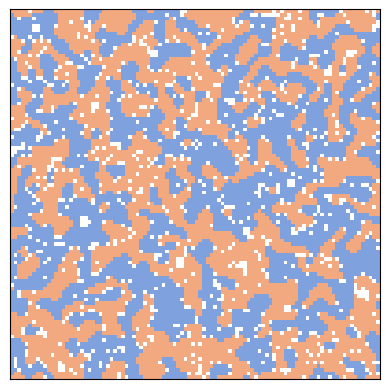

In [34]:
grid = Schelling(n=100, p=0.4)
grid.animate(frames=100, interval=0.1) #animate这个function里面有step会自己跳动

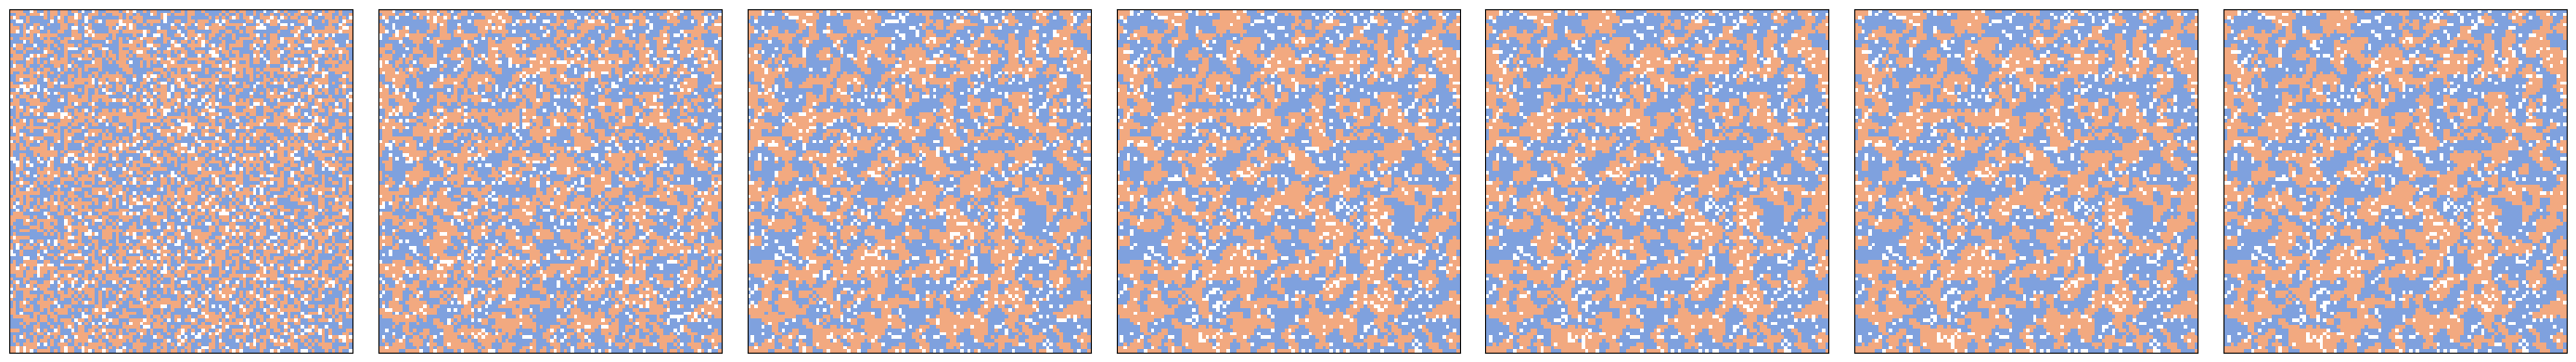

In [32]:
from utils import three_frame
from utils import number_frame

grid = Schelling(n=100, p=0.3)
# three_frame(grid, [0, 2, 8]) #step0,0+2,0+2+8
number_frame(grid,[0,2,3,5,5,10,10],7)